# 02 · RFM-таблица

Шаг 3 плана. Таблица на клиента по конвенции `lifetimes`; определения — в docstring `src/features.py`. Данные: вся история, cutoff — конец данных.

In [1]:
import sys
sys.path.insert(0, '../..'); sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from paths import CASE_LTV, figures
from data import CLEAN_PARQUET
from features import build_features, cohort_tables, calendar_retention
FIG = figures(CASE_LTV); FIG.mkdir(parents=True, exist_ok=True)
tx = pd.read_parquet(CLEAN_PARQUET)
feats = build_features(tx)
feats.describe().T[['count','mean','50%','max']].round(1)

,count,mean,50%,max
first_purchase,5852,2010-08-23 00:13:51.705399,2010-06-28 13:35:30,2011-12-09 12:16:00
frequency,5852.0,4.61825,2.0,246.0
recency,5852.0,273.807929,223.0,738.0
T,5852.0,473.540328,529.0,738.0
recency_rfm,5852.0,199.732399,95.0,738.0
monetary,4179.0,442.26026,299.95,168469.6
sales_revenue,5852.0,2916.709282,856.02,580987.04
net_revenue,5852.0,2795.63148,840.245,578408.64


## Проверки целостности

`frequency` пересобирается независимо из сырой таблицы (правило 2 из `conventions.md` §5а): число уникальных дней с покупкой минус один.

In [2]:
raw_sales = tx[~tx.is_cancel]
freq_check = raw_sales.groupby('customer_id').date.apply(lambda s: s.dt.normalize().nunique()) - 1
assert (freq_check.reindex(feats.index) == feats.frequency).all()
assert (feats['T'] >= feats.recency).all()
assert (feats['T'] - feats.recency == feats.recency_rfm).all()
# monetary не определён ровно там, где нет повторных покупок: NaN, а не 0
assert (feats.monetary.isna() == (feats.frequency == 0)).all()
assert (feats.monetary.dropna() > 0).all()
print('ok; клиентов', len(feats), '· frequency = 0:', f'{(feats.frequency == 0).mean():.1%}')

ok; клиентов 5852 · frequency = 0: 28.6%


Доля `frequency = 0` здесь (дни с покупкой) равна 28,6 %, а доля клиентов с одним счётом — 27,6 % (ноутбук 01): часть клиентов делала несколько счетов в один день. Для BG/NBD единицей служит день, поэтому берём 28,6 %.

## Распределения

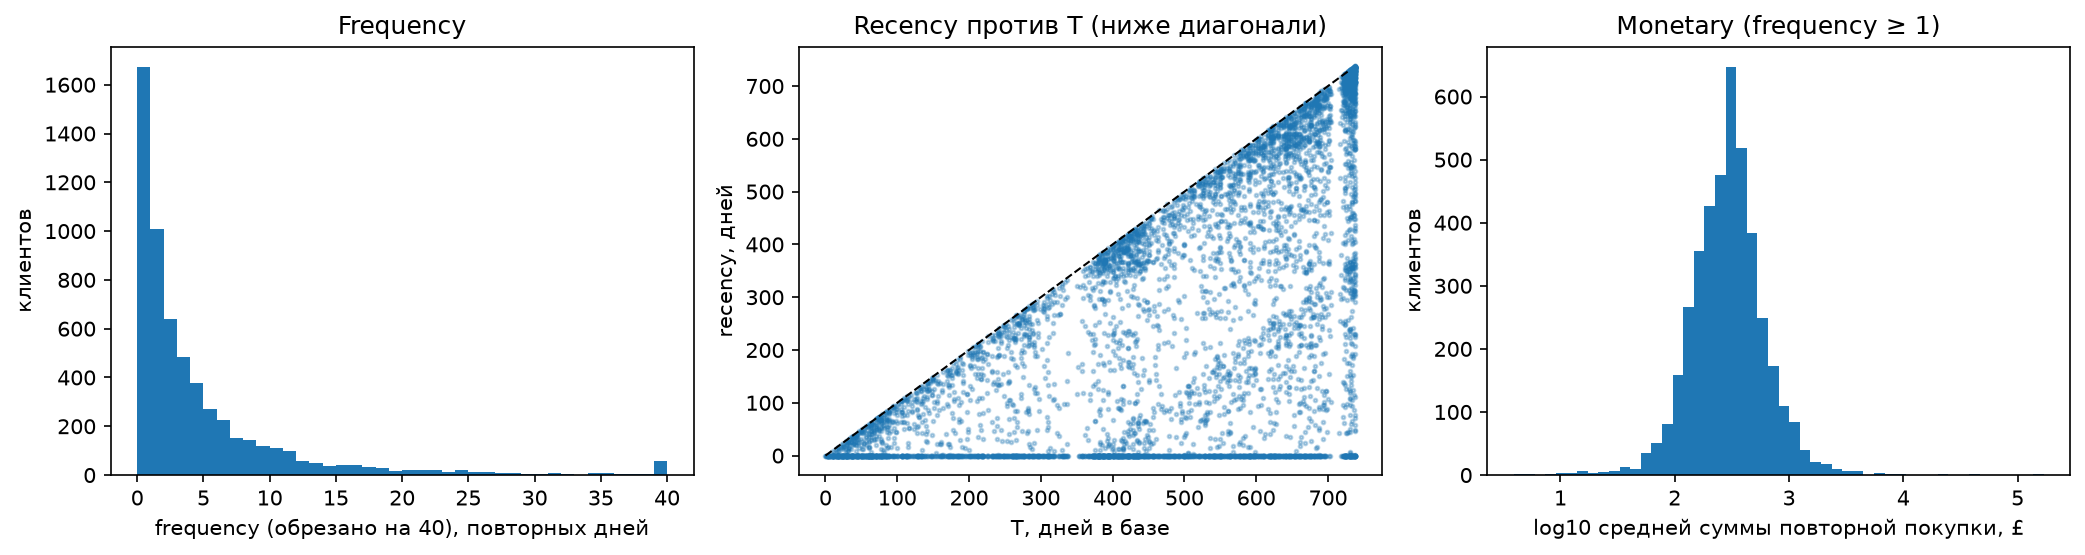

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), dpi=150)
ax[0].hist(feats.frequency.clip(upper=40), bins=40)
ax[0].set(xlabel='frequency (обрезано на 40), повторных дней', ylabel='клиентов', title='Frequency')
ax[1].scatter(feats['T'], feats.recency, s=3, alpha=.3)
ax[1].plot([0, 730], [0, 730], 'k--', lw=1)
ax[1].set(xlabel='T, дней в базе', ylabel='recency, дней', title='Recency против T (ниже диагонали)')
ax[2].hist(np.log10(feats.monetary.dropna()), bins=50)
ax[2].set(xlabel='log10 средней суммы повторной покупки, £', ylabel='клиентов', title='Monetary (frequency ≥ 1)')
fig.tight_layout(); fig.savefig(FIG / '03-rfm-distributions.png'); plt.show()

Слева: тяжёлый правый хвост частоты, 1 673 клиента с `frequency = 0`. В центре: горизонтальная полоса на `recency = 0` — клиенты с одним днём покупки; вертикальная полоса у `T ≈ 730` — клиенты с первой покупкой в декабре 2009 (см. ноутбук 03); точки у диагонали — клиенты, чья последняя покупка близка к cutoff. Справа: monetary в логарифме близок к симметричному (форма похожа на лог-нормальную, формальный тест не проводился).

## Концентрация выручки

Грубая оценка потолка сегментации: какая доля net-выручки приходится на верх базы (по факту всей истории, не по прогнозу).

топ-1% клиентов: 31.1% net-выручки
топ-5% клиентов: 51.1% net-выручки
топ-10% клиентов: 63.2% net-выручки
топ-20% клиентов: 76.8% net-выручки
клиентов с отрицательной net-выручкой: 4


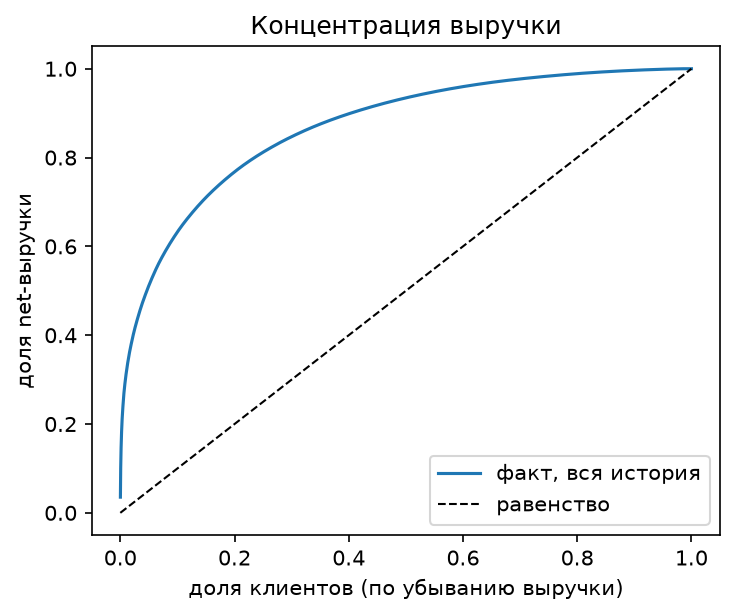

In [4]:
v = feats.net_revenue.sort_values(ascending=False)
share = v.cumsum() / v.sum()
for q in (.01, .05, .10, .20):
    print(f'топ-{q:.0%} клиентов: {share.iloc[int(len(v)*q)-1]:.1%} net-выручки')
print('клиентов с отрицательной net-выручкой:', (feats.net_revenue < 0).sum())
x = np.arange(1, len(v)+1) / len(v)
fig, ax = plt.subplots(figsize=(5, 4.2), dpi=150)
ax.plot(x, share.values, label='факт, вся история'); ax.plot([0,1],[0,1],'k--',lw=1,label='равенство')
ax.set(xlabel='доля клиентов (по убыванию выручки)', ylabel='доля net-выручки', title='Концентрация выручки')
ax.legend(); fig.tight_layout(); fig.savefig(FIG / '04-revenue-concentration.png'); plt.show()

Топ-20 % по факту всей истории собирают 76,8 % net-выручки, топ-10 % — 63,2 %. Это верхняя граница для сегментации по прогнозу на тех же клиентах и тот же период: прогноз не может собрать больше, чем собирает сам факт. Для holdout (шаг 9) аналогичная граница считается отдельно.

In [5]:
feats.to_parquet(__import__('paths').PROCESSED / 'rfm_full.parquet')